## Predicting for my images

In [41]:
import torch
from torch import nn
import numpy as np
import matplotlib.pyplot as plt 
from PIL import Image
from pathlib import Path
import os

In [2]:
from torchvision.models import resnet18
from torchvision.transforms import transforms

In [3]:
device = torch.device("cuda" if torch.cuda.is_available()  else "cpu")
device

device(type='cpu')

In [4]:
class_map = {
    0: "airplane",
    1: "automobile",
    2: "bird",
    3: "cat",
    4: "deer",
    5: "dog",
    6: "frog",
    7: "horse",
    8: "ship",
    9: "truck"
}

#### load the images

In [70]:
image_folder = "my_data/"

images = []  # store the images in this list. 

for file in os.listdir(image_folder):
    if file.lower().endswith(".png"):
        img_path = os.path.join(image_folder, file)

        img = Image.open(img_path)  #fetch the image
        images.append(img)  #store in list

In [71]:
len(images)

19

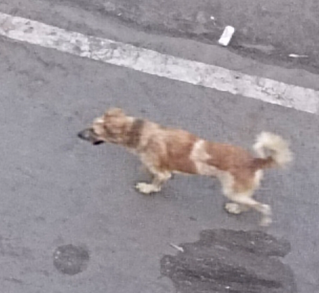

In [72]:
images[0]

In [73]:
print(images[0].size, ":", "width, hight")
print(images[1].size, ":", "width, hight")

(319, 293) : width, hight
(185, 157) : width, hight


my images don't have a fixed width and height. 

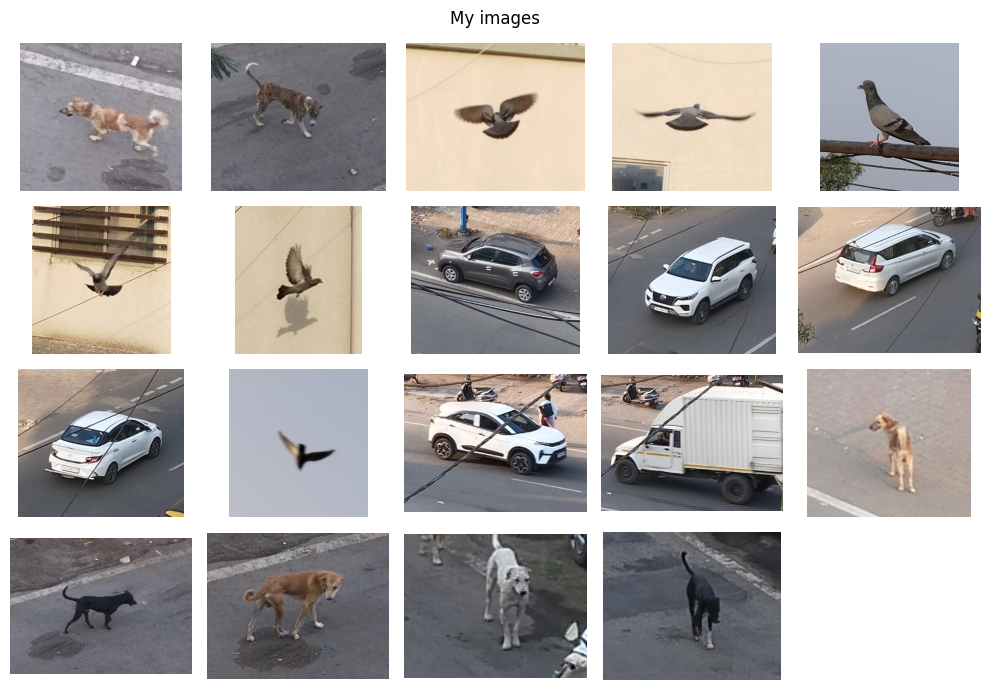

In [91]:
plt.figure(figsize=(10, 7))
for i, img in enumerate(images):
    plt.subplot(4, 5, i+1)
    plt.imshow(img)
    plt.axis("off")

plt.suptitle("My images")
plt.tight_layout()
plt.show()

In [77]:
tf2 = transforms.Compose([
    transforms.Resize((224, 224)),  #resize to 224,224 (bilinear interpolation)
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
]
)

In [78]:
# transform an image
im1 = tf2(images[0])
im1.shape

torch.Size([3, 224, 224])

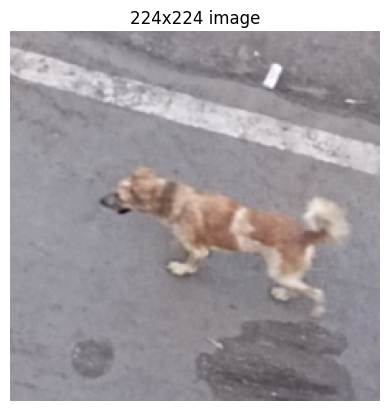

In [79]:
# Inverse normalize for correct visualization. 
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
plt.imshow(inv_normalize(im1).permute(1,2,0))
plt.axis("off")
plt.title("224x224 image")
plt.show()

In [80]:
transformed_images = torch.empty_like(im1)
torch.vstack((transformed_images, transformed_images)).reshape(-1, 3, 224, 224).shape

torch.Size([2, 3, 224, 224])

In [81]:
transformed_images = torch.empty_like(im1)    # create an empty tensor to append the images in a batch

for img in images:
    x = tf2(img)  #gives 3x224x224
    transformed_images = torch.vstack((transformed_images, x))


In [82]:
transformed_images = transformed_images.reshape(-1, 3, 224, 224)
transformed_images.shape

torch.Size([20, 3, 224, 224])

we know the first one is just an empty tensor, so remove the 1st image

In [83]:
transformed_images = transformed_images[1:]
transformed_images.shape

torch.Size([19, 3, 224, 224])

These 23 images are now ready for feeding into the model and get predictions

In [ ]:
# load the resnet architecture (without pretrained weights)
model = resnet18(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 10)

#load the fine tuned weights into a variable
state_dict = torch.load('resnet18_40k.pth', weights_only=True,
                        map_location='cpu')

model.load_state_dict(state_dict)  #update them in model
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [85]:
# Feed into the model to get output logits. 
preds = model(transformed_images)
preds.shape

torch.Size([19, 10])

In [86]:
# get the probabilities
probs = torch.softmax(preds, dim = 1)

In [87]:
# find the integer labels with highest probability
predicted_classes = probs.argmax(axis = 1)
predicted_classes

tensor([2, 5, 2, 2, 2, 2, 2, 2, 1, 1, 0, 2, 2, 9, 2, 4, 5, 3, 5])

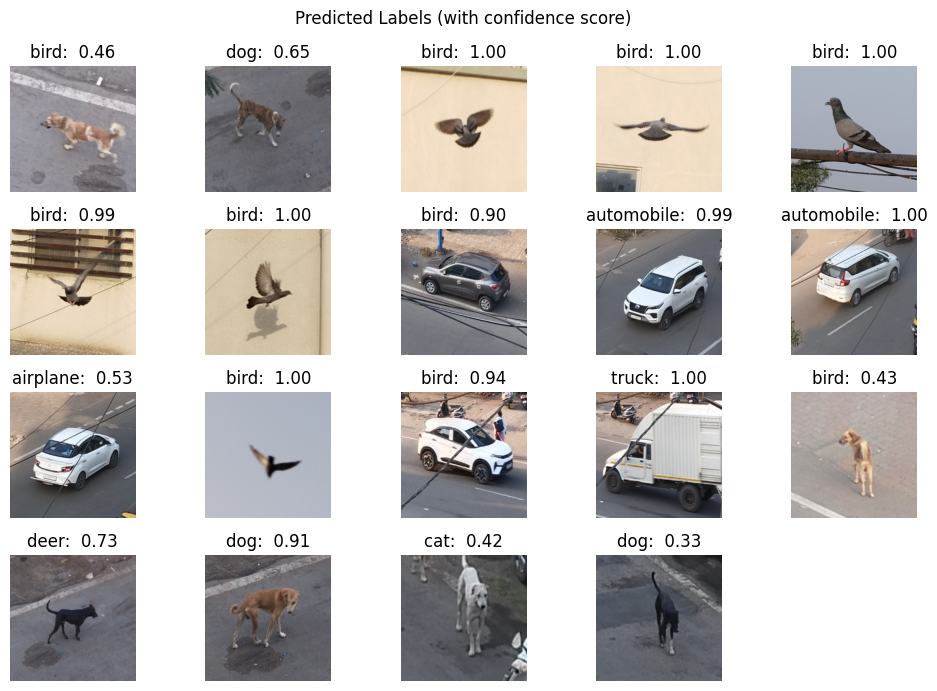

In [90]:
plt.figure(figsize=(10, 7))
for i, img in enumerate(transformed_images):
    plt.subplot(4, 5, i+1)
    plt.imshow(inv_normalize(img).permute(1,2,0))
    plt.title(f"{class_map[predicted_classes[i].item()]}: {round(probs[i].max().item(), 2): .2f}")
    plt.axis("off")

plt.suptitle("Predicted Labels (with confidence score)")
plt.tight_layout()
plt.show()

My images were not very close to the data that the model was trained on, since the model was trained on close-range pictures, but I captured these images from an apartment, pointing my camera downward at objects on the ground

One drawback of CNNs or any neural network models is their explainability. 

For example, here we cannot know exactly why that 3rd image in the second row was classified as a bird with such a high confidence. 